Introduction

Machine learning models can sometimes behave like black boxes, making it difficult to understand how individual features influence their predictions.

Explainable Artificial Intelligence (XAI) helps improve model interpretability by providing insights into how predictions are generated.

In this notebook, SHAP (SHapley Additive exPlanations) is used to interpret the Support Vector Regression model. SHAP values are calculated to examine the contribution of individual input features to the model's predicted menstrual cycle length.

Summary and feature importance plots are generated to identify which features have a greater influence on the model's predictions.

In [2]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

In [3]:
# Load cleaned dataset

df = pd.read_csv("../Dataset/menstrual_health_cleaned.csv")

print("Dataset shape:", df.shape)

df.head()

# Separate independent and dependent variables

X = df.drop(columns=[
    "Length_of_cycle",
    "Mean_of_length_of_cycle",
    "Estimated_day_of_ovulution",
    "Weight"
])

y = df["Length_of_cycle"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)


# Identify feature types

categorical_features = ["Unusual_Bleeding"]

numerical_features = [
    "number_of_peak",
    "Age",
    "Length_of_Leutal_Phase",
    "Length_of_menses",
    "BMI",
    "Menses_score"
]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)


# Numerical preprocessing

numerical_transformer = StandardScaler()

# Categorical preprocessing

categorical_transformer = OneHotEncoder(
    drop="if_binary",
    handle_unknown="ignore"
)

# Combine preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


# Create SVR pipeline

svr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", SVR(
        kernel="rbf",
        C=1.0,
        epsilon=0.1
    ))
])

# Train the model

svr_pipeline.fit(X, y)

print("SVR model trained successfully!")


Dataset shape: (81, 11)
Feature shape: (81, 7)
Target shape: (81,)
Numerical features: ['number_of_peak', 'Age', 'Length_of_Leutal_Phase', 'Length_of_menses', 'BMI', 'Menses_score']
Categorical features: ['Unusual_Bleeding']
Preprocessing pipeline created successfully!
SVR model trained successfully!


In [4]:
# Extract preprocessing information

fitted_preprocessor = svr_pipeline.named_steps["preprocessor"]

feature_names = fitted_preprocessor.get_feature_names_out()

print("Processed feature names:")

for feature in feature_names:
    print(feature)

Processed feature names:
num__number_of_peak
num__Age
num__Length_of_Leutal_Phase
num__Length_of_menses
num__BMI
num__Menses_score
cat__Unusual_Bleeding_yes


In [5]:
# Transform the dataset

X_processed = fitted_preprocessor.transform(X)

# Convert into DataFrame

X_processed_df = pd.DataFrame(
    X_processed,
    columns=feature_names
)

print("Processed dataset shape:", X_processed_df.shape)

X_processed_df.head()

Processed dataset shape: (81, 7)


,num__number_of_peak,num__Age,num__Length_of_Leutal_Phase,num__Length_of_menses,num__BMI,num__Menses_score,cat__Unusual_Bleeding_yes
0,0.683265,-0.920358,-1.151102,-0.060368,1.537696,0.531738,0.0
1,2.102353,-0.920358,-0.844394,0.917596,1.537696,1.379587,1.0
2,-0.735824,-0.230089,0.075730,-1.038332,0.054316,-1.163961,0.0
3,0.683265,-0.230089,0.382439,0.917596,1.234277,-0.316112,0.0
4,-0.735824,-0.230089,0.689147,-0.060368,-0.080537,1.379587,0.0


In [6]:
# Create background dataset

background = shap.sample(
    X_processed_df,
    20,
    random_state=42
)

# Create prediction function

model = svr_pipeline.named_steps["model"]

explainer = shap.KernelExplainer(
    model.predict,
    background
)

print("SHAP explainer created successfully!")

SHAP explainer created successfully!


In [7]:
# Calculate SHAP values

shap_values = explainer.shap_values(
    X_processed_df,
    nsamples=100
)

print("SHAP values calculated successfully!")

  0%|          | 0/81 [00:00<?, ?it/s]

100%|██████████| 81/81 [00:04<00:00, 18.76it/s]

SHAP values calculated successfully!


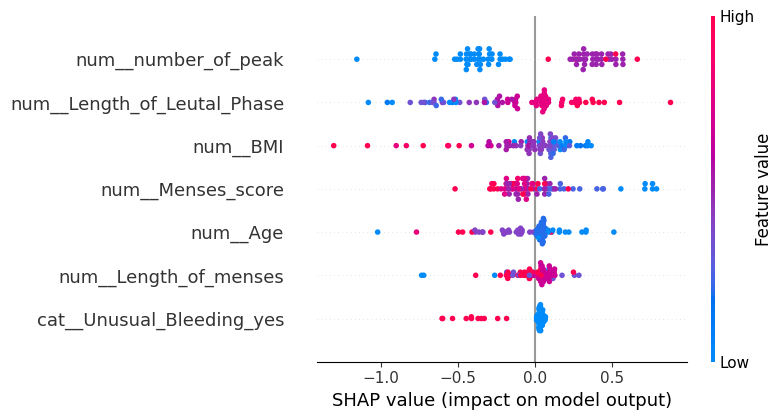

In [8]:
# Generate SHAP summary plot

shap.summary_plot(
    shap_values,
    X_processed_df,
    show=True
)

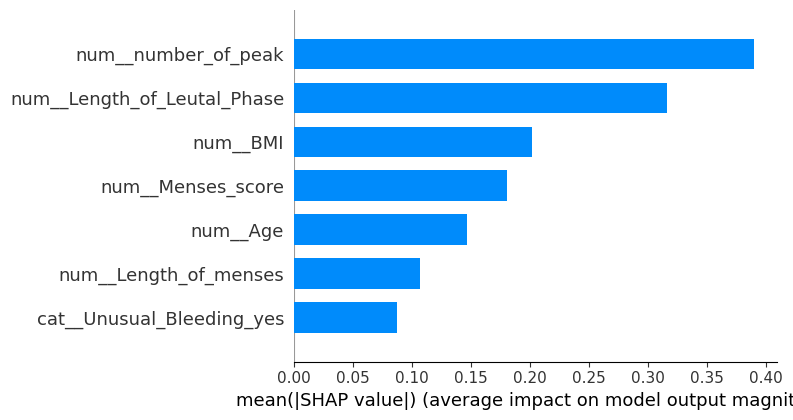

In [9]:
# Generate SHAP feature importance plot

shap.summary_plot(
    shap_values,
    X_processed_df,
    plot_type="bar",
    show=True
)

## Interpretation of SHAP Results

SHAP (SHapley Additive exPlanations) was used to investigate the contribution of individual features to the menstrual cycle length predictions generated by the Support Vector Regression model.

### SHAP Summary Plot

The SHAP summary plot illustrates the direction and magnitude of feature contributions to individual predictions.

The results indicate that `number_of_peak` has the highest influence on model predictions, followed by `Length_of_Leutal_Phase` and BMI.

Higher values of `number_of_peak` generally show positive SHAP values, indicating an increase in the model's predicted cycle length. In contrast, higher BMI values generally show negative SHAP values, suggesting a tendency to decrease predicted cycle length.

The contributions of other features, including `Menses_score`, Age and `Length_of_menses`, vary across individual records.

### SHAP Feature Importance

The feature importance plot ranks the seven input features based on their mean absolute SHAP values.

The ranking indicates that:

1. `number_of_peak` has the highest average contribution to model predictions.
2. `Length_of_Leutal_Phase` is the second most influential feature.
3. BMI and `Menses_score` show moderate contributions.
4. Age and `Length_of_menses` have comparatively lower contributions.
5. `Unusual_Bleeding` has the lowest average contribution.

### Overall Observation

The SHAP analysis suggests that `number_of_peak` and `Length_of_Leutal_Phase` contribute most strongly to the predictions generated by the selected SVR model.

However, these findings represent the model's learned patterns and should not be interpreted as biological causation or clinical relationships.

Furthermore, since the model was trained on a relatively small dataset, the feature contributions require further investigation using larger datasets and additional validation.

## Conclusion

SHAP-based explainability was successfully implemented to investigate the feature contributions of the Support Vector Regression model developed for menstrual cycle length prediction.

The analysis identified `number_of_peak` as the most influential feature, followed by `Length_of_Leutal_Phase`, BMI and `Menses_score`.

The SHAP summary plot provided insights into the direction of individual feature contributions, while the feature importance plot highlighted the overall ranking of the selected features.

These results improve the interpretability of the machine learning model by showing how different input features contribute to its predictions.

However, SHAP values explain the behaviour of the trained model rather than establishing biological causation. The findings should also be interpreted cautiously because of the limited dataset size and the model's previously observed predictive limitations.

Overall, this analysis demonstrates the application of Explainable AI in understanding machine learning predictions involving menstrual health data.